# 📦 Análise de Performance Logística — E-commerce Olist

**Objetivo:** entender onde a operação de entregas falha, quanto isso custa em satisfação do cliente
e onde estão as oportunidades de melhoria.

**Base:** ~96 mil pedidos entregues entre jan/2017 e ago/2018 (dados públicos e reais da Olist).

**Perguntas de negócio**
1. Qual o nível de serviço atual (entregas no prazo, lead time, frete)?
2. Quais regiões e estados concentram os atrasos?
3. Em qual etapa do processo o tempo é gasto?
4. Quanto o atraso impacta a avaliação do cliente?
5. O atraso nasce no vendedor ou no transporte?
6. Como a operação se comportou ao longo do tempo (picos de demanda)?

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import os; os.chdir(RAIZ)
from rodar_sql import comandos, preparar_base

con = duckdb.connect()
preparar_base(con)  # cria a tabela base_entregas (sql/01_base_entregas.sql)

def consulta(arquivo, n=0):
    """Executa a n-ésima consulta de um arquivo da pasta sql/ e devolve um DataFrame."""
    return con.sql(comandos(RAIZ / "sql" / arquivo)[n]).df()

# Estilo dos gráficos
AZUL, CINZA, VERMELHO = "#0EA5E9", "#CBD5E1", "#EF4444"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10,
})
IMG = RAIZ / "images"
IMG.mkdir(exist_ok=True)

## 1. Visão geral

Base preparada em SQL (`sql/01_base_entregas.sql`): uma linha por pedido, com prazos de cada etapa,
frete, rota (origem → destino), pontualidade e nota da avaliação.

In [2]:
kpis = consulta("02_kpis_gerais.sql")
kpis.T.rename(columns={0: "valor"})

,valor
pedidos_entregues,96188.00
pct_entregue_no_prazo,93.20
lead_time_mediano_dias,10.20
lead_time_medio_dias,12.50
prazo_prometido_medio_dias,24.30
folga_media_dias,11.70
frete_pct_valor_produtos,16.70
frete_medio_por_pedido,22.83
pct_vendedor_postou_no_prazo,91.10
nota_media,4.16


> **Leitura:** 93% dos pedidos chegam no prazo, mas a Olist promete em média **24 dias** para entregas
> que levam **12,5**: uma folga de quase 12 dias. A pontualidade alta é, em parte, resultado de um
> prazo prometido muito conservador, o que pode custar conversão no checkout.

## 2. Onde estão os atrasos?

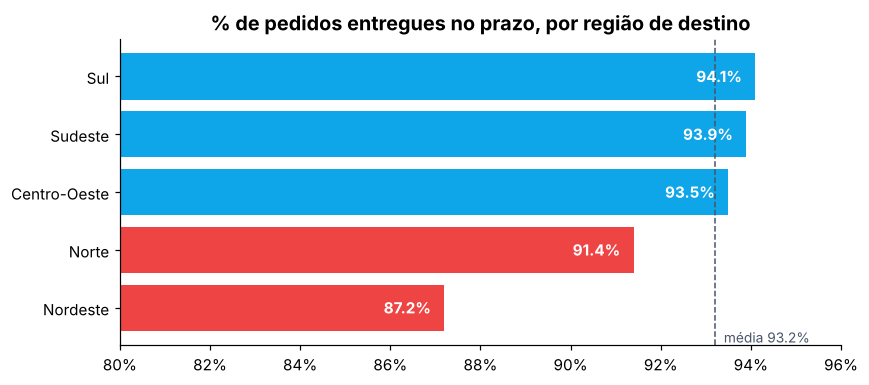

,regiao,pedidos,pct_no_prazo,lead_time_medio,prazo_prometido_medio,frete_medio,frete_pct_produto
0,Nordeste,9013,87.2,20.0,31.2,36.06,21.8
1,Norte,1791,91.4,22.6,38.1,41.34,22.7
2,Centro-Oeste,5610,93.5,15.0,27.2,26.63,17.7
3,Sudeste,66009,93.9,10.7,22.2,19.88,15.2
4,Sul,13765,94.1,14.0,27.0,24.38,17.7


In [3]:
regiao = consulta("03_pontualidade_por_regiao.sql", 0).sort_values("pct_no_prazo")
media = kpis.loc[0, "pct_entregue_no_prazo"]

fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [VERMELHO if v < media else AZUL for v in regiao["pct_no_prazo"]]
ax.barh(regiao["regiao"], regiao["pct_no_prazo"], color=cores)
ax.axvline(media, color="#475569", ls="--", lw=1)
ax.text(media + 0.2, -0.6, f"média {media:.1f}%", color="#475569", fontsize=9)
for y, v in enumerate(regiao["pct_no_prazo"]):
    ax.text(v - 0.3, y, f"{v:.1f}%", va="center", ha="right", color="white", fontweight="bold")
ax.set_xlim(80, 96)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% de pedidos entregues no prazo, por região de destino")
plt.tight_layout(); plt.savefig(IMG / "01_no_prazo_por_regiao.png", bbox_inches="tight"); plt.show()
regiao

In [4]:
consulta("03_pontualidade_por_regiao.sql", 1)  # 10 piores UFs (mín. 300 pedidos)

,uf,regiao,pedidos,pct_no_prazo,lead_time_medio
0,AL,Nordeste,396,78.5,24.5
1,MA,Nordeste,712,82.4,21.5
2,SE,Nordeste,332,84.6,21.4
3,PI,Nordeste,475,86.1,19.4
4,CE,Nordeste,1272,86.2,21.2
5,BA,Nordeste,3253,87.8,19.3
6,RJ,Sudeste,12308,87.9,15.3
7,PA,Norte,942,88.7,23.8
8,ES,Sudeste,1992,89.3,15.8
9,PB,Nordeste,516,89.5,20.4


> **Leitura:** o **Nordeste** tem a pior pontualidade (87%) e concentra 6 das 10 piores UFs.
> Alagoas (78,5%) e Maranhão (82,4%) lideram os atrasos. O ponto fora da curva é o **Rio de Janeiro**:
> mesmo no Sudeste, entrega no prazo só 87,9% das vezes, com 12 mil pedidos. Pelo volume, é o estado
> com maior número absoluto de atrasos e merece investigação própria (transportadora, áreas de risco).

## 3. Em qual etapa o tempo é gasto?

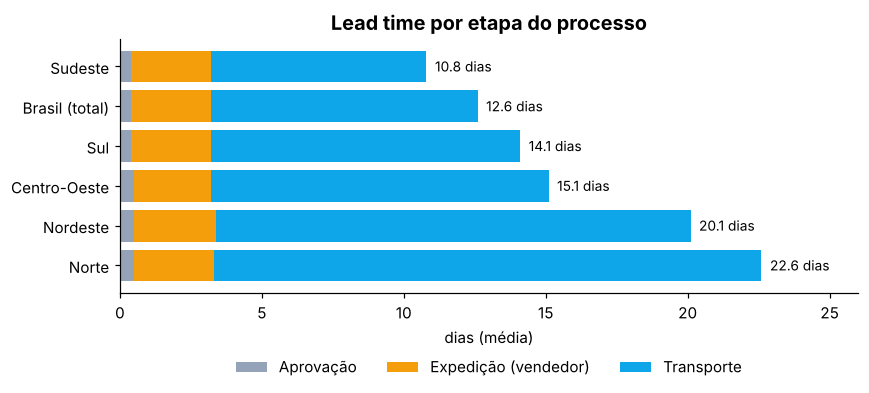

,regiao,pedidos,aprovacao,expedicao_vendedor,transporte,lead_time_total
5,Norte,1772,0.5,2.8,19.3,22.6
4,Nordeste,8900,0.5,2.9,16.7,20.1
3,Centro-Oeste,5527,0.5,2.7,11.9,15.1
2,Sul,13560,0.4,2.8,10.9,14.1
1,Brasil (total),94938,0.4,2.8,9.4,12.6
0,Sudeste,65179,0.4,2.8,7.6,10.8


In [5]:
etapas = consulta("04_etapas_do_processo.sql").sort_values("lead_time_total", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
esquerda = pd.Series(0.0, index=etapas.index)
for col, cor, rotulo in [("aprovacao", "#94A3B8", "Aprovação"),
                         ("expedicao_vendedor", "#F59E0B", "Expedição (vendedor)"),
                         ("transporte", AZUL, "Transporte")]:
    ax.barh(etapas["regiao"], etapas[col], left=esquerda, color=cor, label=rotulo)
    esquerda += etapas[col]
for y, total in enumerate(etapas["lead_time_total"]):
    ax.text(total + 0.3, y, f"{total:.1f} dias", va="center", fontsize=9)
ax.set_xlabel("dias (média)")
ax.set_title("Lead time por etapa do processo")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
ax.set_xlim(0, 26)
plt.tight_layout(); plt.savefig(IMG / "02_etapas_do_processo.png", bbox_inches="tight"); plt.show()
etapas

> **Leitura:** o tempo de **expedição do vendedor é igual em todas as regiões** (~2,8 dias). A diferença
> está toda no **transporte**, que representa ~74% do lead time e vai de 7,6 dias (Sudeste) a 19,3 dias
> (Norte). O gargalo das regiões distantes é a malha de transporte, não o vendedor.

## 4. Quanto o atraso custa em satisfação?

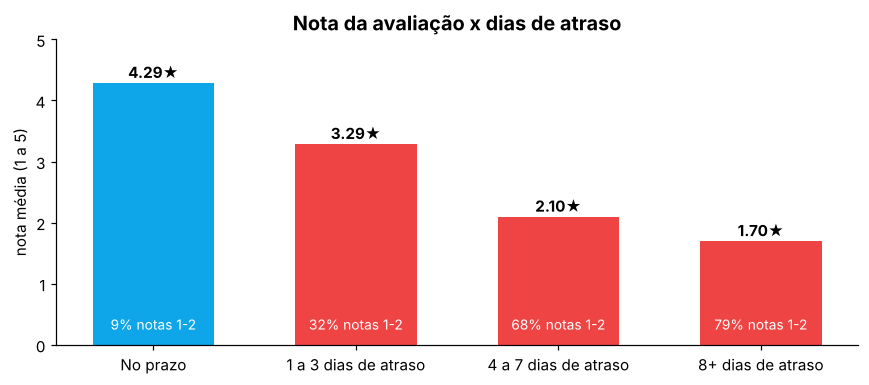

,faixa_atraso,pedidos,nota_media,pct_notas_1_ou_2
0,1. No prazo,89168,4.29,9.2
1,2. 1 a 3 dias de atraso,1851,3.29,32.1
2,3. 4 a 7 dias de atraso,1747,2.10,67.7
3,4. 8+ dias de atraso,2779,1.70,79.3


In [6]:
aval = consulta("05_atraso_vs_avaliacao.sql")

fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [AZUL] + [VERMELHO] * (len(aval) - 1)
ax.bar(aval["faixa_atraso"].str[3:], aval["nota_media"], color=cores, width=0.6)
for x, (nota, ruim) in enumerate(zip(aval["nota_media"], aval["pct_notas_1_ou_2"])):
    ax.text(x, nota + 0.08, f"{nota:.2f}★", ha="center", fontweight="bold")
    ax.text(x, 0.25, f"{ruim:.0f}% notas 1-2", ha="center", color="white", fontsize=9)
ax.set_ylim(0, 5)
ax.set_ylabel("nota média (1 a 5)")
ax.set_title("Nota da avaliação x dias de atraso")
plt.tight_layout(); plt.savefig(IMG / "03_atraso_vs_avaliacao.png", bbox_inches="tight"); plt.show()
aval

> **Leitura:** este é o achado mais forte. A nota média cai de **4,29** (no prazo) para **1,70** com
> 8+ dias de atraso, e quase **8 em cada 10** desses clientes dão nota 1 ou 2. Basta **1 a 3 dias** de
> atraso para a nota cair um ponto inteiro. Pontualidade é o principal motor da satisfação.

## 5. O atraso nasce no vendedor ou no transporte?

In [7]:
display(consulta("06_rota_e_vendedor.sql", 0))
consulta("06_rota_e_vendedor.sql", 1)

,tipo_rota,pedidos,pct_no_prazo,lead_time_medio,frete_pct_produto
0,Mesmo estado,34611,95.5,7.9,13.0
1,Interestadual,61577,91.9,15.1,18.3


,postagem_vendedor,pedidos,pct_entregue_no_prazo
0,Postou atrasado,8575,78.9
1,Postou no prazo,87613,94.6


> **Leitura:**
> - Quando o **vendedor posta atrasado**, a chance de entrega no prazo cai de 94,6% para **78,9%**.
>   Cerca de **28% de todos os atrasos** começam com uma postagem fora do prazo.
> - Vendas **interestaduais** levam quase o dobro do tempo (15,1 x 7,9 dias) e pagam mais frete
>   proporcional (18,3% x 13,0% do valor dos produtos).

## 6. Evolução no tempo

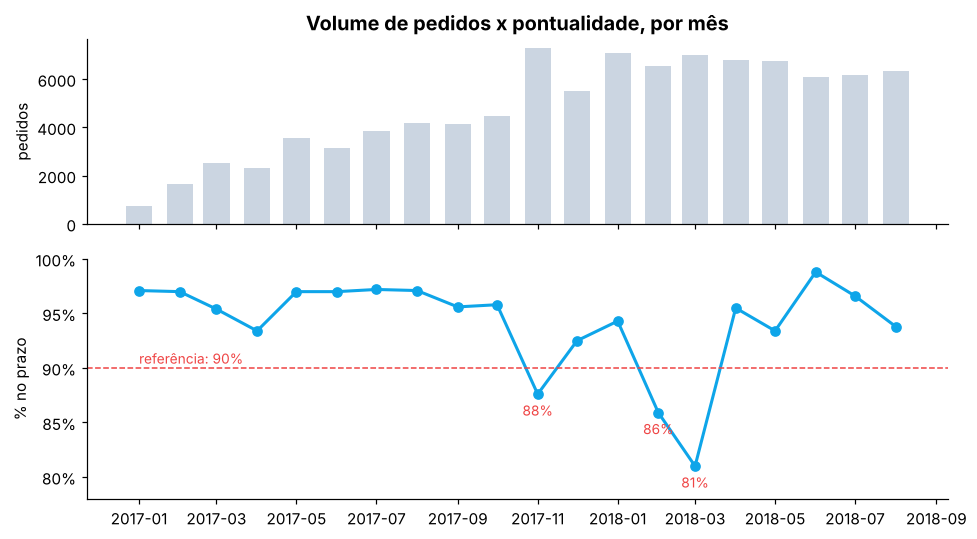

In [8]:
mensal = consulta("07_evolucao_mensal.sql")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
ax1.bar(mensal["mes"], mensal["pedidos"], width=20, color=CINZA)
ax1.set_ylabel("pedidos")
ax1.set_title("Volume de pedidos x pontualidade, por mês")
ax2.plot(mensal["mes"], mensal["pct_no_prazo"], color=AZUL, marker="o", lw=2)
ax2.axhline(90, color=VERMELHO, ls="--", lw=1)
ax2.text(mensal["mes"].iloc[0], 90.4, "referência: 90%", color=VERMELHO, fontsize=9)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_ylabel("% no prazo")
ax2.set_ylim(78, 100)
for _, linha in mensal[mensal["pct_no_prazo"] < 90].iterrows():
    ax2.annotate(f"{linha['pct_no_prazo']:.0f}%", (linha["mes"], linha["pct_no_prazo"]),
                 textcoords="offset points", xytext=(0, -14), ha="center", color=VERMELHO, fontsize=9)
plt.tight_layout(); plt.savefig(IMG / "04_evolucao_mensal.png", bbox_inches="tight"); plt.show()

> **Leitura:** a pontualidade despenca em **nov/2017** (Black Friday: pico de 7,3 mil pedidos, 87,6%
> no prazo) e em **fev–mar/2018** (81% em março). A operação não acompanhou os picos de demanda.
> Planejamento de capacidade para datas sazonais é uma oportunidade clara.

## 7. Conclusões e recomendações

| # | Achado | Recomendação |
|---|---|---|
| 1 | Atraso derruba a nota de 4,29 para até 1,70 | Tratar pontualidade como KPI principal de experiência do cliente |
| 2 | Nordeste (87%) e RJ (88%) concentram os atrasos | Revisar transportadoras/rotas nesses destinos; avaliar CD ou parceiro regional no Nordeste |
| 3 | Transporte é ~74% do lead time; expedição do vendedor é igual em todas as regiões | Focar melhorias na malha de transporte, não no vendedor, para N/NE |
| 4 | Postagem atrasada do vendedor derruba o on-time para 79% | Monitorar e alertar vendedores que postam fora do prazo-limite |
| 5 | Prazo prometido tem ~12 dias de folga | Testar prazos mais precisos por região (ganho de conversão) |
| 6 | Quedas em Black Friday e fev–mar/2018 | Planejar capacidade logística antes de picos sazonais |

**Limitações:** a base não informa a transportadora nem o modal; ~1,3% dos pedidos tinham datas
inconsistentes e foram excluídos da análise de etapas; a avaliação reflete a experiência total, não só a entrega.